# Teammate 2 — AR25 level 2 exploration

Level 1 was solved in `teammate_2_exploration.ipynb` (run `20261120T013551Z`, experiment E09):
10 × `ACTION2` then 5 × `ACTION3` puts the yellow L on the static L and completes level 1.

This notebook uses those 15 moves **only to reach level 2**, then runs controlled experiments **from the start of level 2**.
Same rules as before: no hidden source code, every run writes to a new folder
`data/raw/exploration/level2_<RUN_ID>/`, unsuccessful experiments are kept, facts and hypotheses are separated.

**First look at level 2** (last frame of E09, run `20261120T013551Z`) — *observations, not interpretations*:
- the yellow shape (colour 4) is now on the **left** of the white bar, the dotted grey shape (colour 5 with black dots) on the **right**;
- the static target (colour 11) has the same shape as the yellow one and sits bottom-left;
- the white bar has moved to x = 36–38 and now contains black dots (colour 0);
- the counter column x = 63 is empty again.

## 0. Setup

In [1]:
import json
import platform
from collections import Counter, deque
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from arc_agi import Arcade
from arcengine import GameAction

GAME_ID = "ar25-0c556536"
SEED = 0
TERMINAL_STATES = {"WIN", "GAME_OVER"}

# Moves that solved level 1 (teammate_2_exploration.ipynb, E09, run 20261120T013551Z)
SOLVE_LEVEL_1 = [("ACTION2", {})] * 10 + [("ACTION3", {})] * 5

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "scripts").exists():
    raise RuntimeError(f"Start Jupyter from the repository root (current: {ROOT})")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT = ROOT / "data" / "raw" / "exploration" / f"level2_{RUN_ID}"
FRAMES_DIR = OUT / "frames"
IMAGES_DIR = OUT / "images"
REPORTS_DIR = ROOT / "reports"
for d in (FRAMES_DIR, IMAGES_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_LOG = OUT / "experiments.jsonl"
FAILED_LOG = OUT / "unsuccessful_experiments.jsonl"

print("Run ID     :", RUN_ID)
print("Output dir :", OUT.relative_to(ROOT))
print("Python     :", platform.python_version(), "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

Run ID     : 20261120T020357Z
Output dir : data\raw\exploration\level2_20261120T020357Z
Python     : 3.13.17 | numpy 2.5.5 | matplotlib 3.11.2


Helpers (identical to the level-1 notebook).

In [2]:
# ---------- display helpers ----------
# 16-colour palette approximating the ARC-AGI-3 renderer (display only; analysis uses raw integers).
PALETTE = ["#FFFFFF", "#CCCCCC", "#999999", "#666666", "#333333", "#000000", "#E53AA3", "#FF7BCC",
           "#F93C31", "#1E93FF", "#88D8F1", "#FFDC00", "#FF851B", "#921231", "#4FCC30", "#A356D6"]
CMAP = ListedColormap(PALETTE)


def last_frame(obs):
    return np.array(obs.frame[-1])


def state_name(obs):
    s = obs.state
    return getattr(s, "value", None) or getattr(s, "name", None) or str(s)


def show_frame(frame, ax, title=""):
    ax.imshow(frame, cmap=CMAP, vmin=0, vmax=15, interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.set_xticks(range(0, frame.shape[1], 8))
    ax.set_yticks(range(0, frame.shape[0], 8))
    ax.tick_params(labelsize=6)


def show_diff(before, after, ax, title="changed cells"):
    ax.imshow(before, cmap=CMAP, vmin=0, vmax=15, interpolation="nearest", alpha=0.35)
    mask = np.ma.masked_where(before == after, np.ones_like(before))
    ax.imshow(mask, cmap=ListedColormap(["#FF00FF"]), interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.tick_params(labelsize=6)


# ---------- analysis helpers ----------
# Observed in run 20261120T012831Z: column x=63 is a status bar whose cells turn from colour 11 to 5,
# one per action (a counter). It is excluded when we ask "did the objects return to their start position?".
COUNTER_COL = 63


def play_area(frame):
    return frame[:, :COUNTER_COL]


def counter_cells(frame, initial):
    return int((frame[:, COUNTER_COL] != initial[:, COUNTER_COL]).sum())

def change_summary(before, after):
    # Factual description of what changed between two frames.
    if before.shape != after.shape:
        return {"shape_changed": True, "before_shape": list(before.shape), "after_shape": list(after.shape),
                "changed_cells": None, "bbox_xyxy": None, "color_transitions": {}}
    diff = before != after
    n = int(diff.sum())
    bbox = None
    transitions = {}
    if n:
        ys, xs = np.where(diff)
        bbox = [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]
        pairs = Counter(zip(before[diff].tolist(), after[diff].tolist()))
        transitions = {f"{a}->{b}": c for (a, b), c in pairs.most_common()}
    return {"shape_changed": False, "changed_cells": n, "bbox_xyxy": bbox, "color_transitions": transitions}


def find_objects(frame, background=None, min_size=1):
    # 4-connected components of identical colour, excluding the background (most frequent colour).
    if background is None:
        background = Counter(frame.ravel().tolist()).most_common(1)[0][0]
    h, w = frame.shape
    seen = np.zeros_like(frame, dtype=bool)
    objects = []
    for y in range(h):
        for x in range(w):
            if seen[y, x] or frame[y, x] == background:
                continue
            color = int(frame[y, x])
            q, cells = deque([(y, x)]), []
            seen[y, x] = True
            while q:
                cy, cx = q.popleft()
                cells.append((cy, cx))
                for ny, nx in ((cy + 1, cx), (cy - 1, cx), (cy, cx + 1), (cy, cx - 1)):
                    if 0 <= ny < h and 0 <= nx < w and not seen[ny, nx] and frame[ny, nx] == color:
                        seen[ny, nx] = True
                        q.append((ny, nx))
            if len(cells) < min_size:
                continue
            ys = [c[0] for c in cells]
            xs = [c[1] for c in cells]
            # click point = the object cell closest to its centroid (guaranteed to be on the object)
            cy, cx = np.mean(ys), np.mean(xs)
            py, px = min(cells, key=lambda c: (c[0] - cy) ** 2 + (c[1] - cx) ** 2)
            objects.append({"color": color, "size": len(cells),
                            "bbox_xyxy": [min(xs), min(ys), max(xs), max(ys)],
                            "click_xy": {"x": int(px), "y": int(py)}})
    return background, objects

In [3]:
# ---------- object tracking for level 2 ----------
# Colours observed on the level-2 start frame (run 20261120T013551Z):
#   4 = yellow shape, 5 = dotted grey shape (row 63 is a static grey floor, excluded),
#   10 = white bar (with black dots, colour 0), 11 = static target (column 63 = counter, excluded).
def positions(frame):
    play = play_area(frame)[:63, :]          # drop counter column and floor row
    out = {}
    for name, color in (("yellow", 4), ("grey", 5), ("bar", 10), ("target", 11)):
        ys, xs = np.where(play == color)
        out[name] = None if len(xs) == 0 else {
            "x0": int(xs.min()), "y0": int(ys.min()), "x1": int(xs.max()), "y1": int(ys.max()), "cells": int(len(xs))}
    return out


def displacement(before, after):
    pb, pa = positions(before), positions(after)
    d = {}
    for k in pb:
        if pb[k] is None or pa[k] is None:
            d[k] = "missing"
        else:
            d[k] = (pa[k]["x0"] - pb[k]["x0"], pa[k]["y0"] - pb[k]["y0"])
    return d

## 1. Reach level 2

`goto_level2()` resets the game and, if needed, replays the 15 level-1 moves. It checks that `levels_completed == 1`
and that the frame is identical to the first level-2 frame recorded in this run.

INFO:arc_agi.scorecard:Initialized ScorecardManager with idle_for=0:15:00 and max_open_for=3 days, 0:00:00
2026-11-20 03:03:58 | INFO | Got anonymous API key: 8dfea985-9684-4d8a-8454-5eaa2a81a63c
2026-11-20 03:03:58 | INFO | You can register for an API key at https://arcprize.org
2026-11-20 03:03:58 | INFO | Successfully fetched 25 environment(s) from API
2026-11-20 03:03:58 | INFO | Created new scorecard: e3619841-bcdd-4601-8bfb-a6706fb6bd45
2026-11-20 03:03:59 | INFO | Successfully fetched metadata for game ar25
2026-11-20 03:03:59 | INFO | Successfully loaded game class Ar25 from environment_files\ar25\0c556536\ar25.py
{
  "game_id": "ar25-0c556536",
  "seed": 0,
  "levels_completed": 1,
  "win_levels": 8,
  "state": "NOT_FINISHED",
  "frame_count": 3,
  "available_actions": [
    "ACTION1",
    "ACTION2",
    "ACTION3",
    "ACTION4",
    "ACTION5",
    "ACTION6",
    "ACTION7"
  ]
}
Reset behaviour: {'levels_after_reset': 0, 'full_reset': True, 'replayed': True, 'identical_to_firs

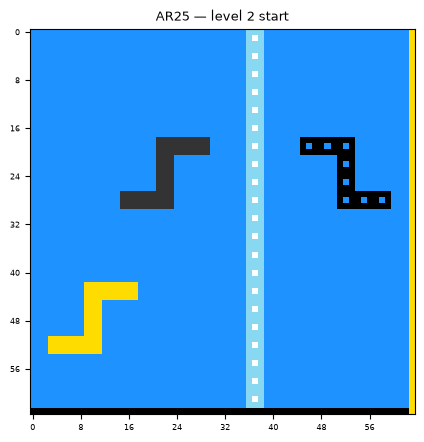

Tracked objects: {
 "yellow": {
  "x0": 15,
  "y0": 18,
  "x1": 29,
  "y1": 29,
  "cells": 72
 },
 "grey": {
  "x0": 45,
  "y0": 18,
  "x1": 59,
  "y1": 29,
  "cells": 64
 },
 "bar": {
  "x0": 36,
  "y0": 0,
  "x1": 38,
  "y1": 62,
  "cells": 168
 },
 "target": {
  "x0": 3,
  "y0": 42,
  "x1": 17,
  "y1": 53,
  "cells": 72
 }
}


In [4]:
arc = Arcade()
env = arc.make(game_id=GAME_ID, seed=SEED, save_recording=False, include_frame_data=True)
if env is None:
    raise RuntimeError("Could not create the AR25 environment")

LEVEL2_START = None
RESET_LOG = []


def goto_level2():
    global LEVEL2_START
    obs = env.reset()
    info = {"levels_after_reset": obs.levels_completed, "full_reset": getattr(obs, "full_reset", None), "replayed": False}
    if obs.levels_completed == 0:
        for name, data in SOLVE_LEVEL_1:
            obs = env.step(GameAction[name], data=data)
        info["replayed"] = True
    if obs.levels_completed != 1:
        raise RuntimeError(f"Expected to be at level 2 (levels_completed=1), got {obs.levels_completed}")
    f = last_frame(obs)
    if LEVEL2_START is None:
        LEVEL2_START = f.copy()
    info["identical_to_first_level2_frame"] = bool(np.array_equal(f, LEVEL2_START))
    RESET_LOG.append(info)
    return obs


obs2 = goto_level2()
frame2 = last_frame(obs2)
np.save(FRAMES_DIR / "level2_start.npy", frame2)
AVAILABLE = [f"ACTION{a}" if isinstance(a, int) else str(a) for a in obs2.available_actions]
SIMPLE_ACTIONS = [a for a in ["ACTION1", "ACTION2", "ACTION3", "ACTION4", "ACTION5", "ACTION7"] if a in AVAILABLE]
ENV_INFO = {"game_id": GAME_ID, "seed": SEED, "levels_completed": obs2.levels_completed, "win_levels": obs2.win_levels,
            "state": state_name(obs2), "frame_count": len(obs2.frame), "available_actions": AVAILABLE}
print(json.dumps(ENV_INFO, indent=2))
print("Reset behaviour:", RESET_LOG[-1])

fig, ax = plt.subplots(figsize=(5, 5))
show_frame(frame2, ax, "AR25 — level 2 start")
fig.savefig(IMAGES_DIR / "level2_start.png", dpi=120, bbox_inches="tight")
plt.show()

BACKGROUND, OBJECTS = find_objects(frame2)
P0 = positions(frame2)
print("Tracked objects:", json.dumps(P0, indent=1))

In [5]:
# Does a second reset (from level 2) restart level 2 or go back to level 1?
again = goto_level2()
print("Second goto_level2():", RESET_LOG[-1])

Second goto_level2(): {'levels_after_reset': 0, 'full_reset': True, 'replayed': True, 'identical_to_first_level2_frame': True}


## 2. Experiment runner (starts every experiment at the beginning of level 2)

In [6]:
RESULTS = {}


def _append_jsonl(path, record):
    with path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")


def run_experiment(exp_id, question, actions, show=True, max_panels=6):
    obs = goto_level2()
    start = last_frame(obs)
    np.save(FRAMES_DIR / f"{exp_id}_step00_start.npy", start)
    steps, error, prev = [], None, obs
    snapshots = [("start", start)]

    for i, (name, data) in enumerate(actions, start=1):
        if state_name(prev) in TERMINAL_STATES:
            error = f"stopped before step {i}: terminal state {state_name(prev)}"
            break
        before = last_frame(prev)
        try:
            res = env.step(GameAction[name], data=data or {})
        except Exception as exc:  # recorded, not hidden
            error = f"step {i} {name} {data}: {type(exc).__name__}: {exc}"
            break
        if res is None:
            error = f"step {i} {name} {data}: env.step returned None"
            break
        files = []
        for k, fr in enumerate(res.frame):
            fn = f"{exp_id}_step{i:02d}_after_{k:02d}.npy"
            np.save(FRAMES_DIR / fn, np.array(fr))
            files.append(fn)
        after = last_frame(res)
        steps.append({
            "step": i, "action": name, "action_data": data or {},
            "after_files": files, "after_frame_count": len(res.frame),
            "state_before": state_name(prev), "state_after": state_name(res),
            "levels_completed": res.levels_completed,
            "counter_cells_used": counter_cells(after, start),
            "play_area_changed_cells": change_summary(play_area(before), play_area(after))["changed_cells"],
            "available_actions": [f"ACTION{a}" if isinstance(a, int) else str(a) for a in res.available_actions],
            "full_reset": getattr(res, "full_reset", None),
            **change_summary(before, after),
        })
        snapshots.append((f"{i}: {name}" + (f" {data}" if data else ""), after))
        prev = res

    final = last_frame(prev)
    net = change_summary(start, final)
    net_play = change_summary(play_area(start), play_area(final))
    final_state = state_name(prev)
    total_changed = sum((s["changed_cells"] or 0) for s in steps)

    if error:
        outcome = "error"
    elif final_state == "GAME_OVER":
        outcome = "game_over"
    elif final_state == "WIN" or (steps and steps[-1]["levels_completed"] > obs.levels_completed):
        outcome = "level_progress"
    elif total_changed == 0:
        outcome = "no_visible_change"
    elif net_play["changed_cells"] == 0:
        outcome = "changed_then_returned_to_start"
    else:
        outcome = "changed"

    record = {
        "run_id": RUN_ID, "experiment_id": exp_id, "question": question,
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "game_id": GAME_ID, "seed": SEED,
        "actions": [{"action": a, "action_data": d or {}} for a, d in actions],
        "steps_executed": len(steps), "steps": steps,
        "net_change": net, "net_change_play_area": net_play,
        "counter_cells_used": counter_cells(final, start), "final_state": final_state, "outcome": outcome, "error": error,
    }
    np.save(FRAMES_DIR / f"{exp_id}_final.npy", final)
    _append_jsonl(EXPERIMENTS_LOG, record)
    if outcome in {"error", "no_visible_change", "game_over"}:
        _append_jsonl(FAILED_LOG, {k: record[k] for k in
                                   ("run_id", "experiment_id", "question", "actions", "outcome", "error", "final_state")})
    RESULTS[exp_id] = record

    # figure
    shown = snapshots if len(snapshots) <= max_panels else snapshots[:max_panels - 1] + [snapshots[-1]]
    fig, axes = plt.subplots(1, len(shown) + 1, figsize=(2.6 * (len(shown) + 1), 2.9))
    for ax, (title, fr) in zip(axes, shown):
        show_frame(fr, ax, title)
    show_diff(start, final, axes[-1], f"net change: {net['changed_cells']} cells")
    fig.suptitle(f"{exp_id} — {outcome}", fontsize=10)
    fig.tight_layout()
    fig.savefig(IMAGES_DIR / f"{exp_id}.png", dpi=110, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

    per_step = [s["changed_cells"] for s in steps]
    print(f"{exp_id}: outcome={outcome} | changed cells per step={per_step} | net={net['changed_cells']} "
          f"| net bbox={net['bbox_xyxy']} | objects net={net_play['changed_cells']} "
          f"| counter cells={counter_cells(final, start)} | final state={final_state}" + (f" | ERROR: {error}" if error else ""))
    return record





def moves_table(r):
    # per-step displacement of every tracked object, from the saved frames
    prev = np.load(FRAMES_DIR / f"{r['experiment_id']}_step00_start.npy")
    rows = []
    for s in r["steps"]:
        cur = np.load(FRAMES_DIR / s["after_files"][-1])
        rows.append((s["step"], s["action"], s["action_data"], displacement(prev, cur)))
        prev = cur
    return rows


def print_moves(r):
    for step, a, d, disp in moves_table(r):
        print(f"   step {step:>2} {a:<8} {str(d or ''):<18} " + "  ".join(f"{k}={v}" for k, v in disp.items()))

## 3. Controlled experiments on level 2

### L2_E01 — Each simple action once
*Question:* do the actions still move the yellow and grey shapes the same way as in level 1?
Displacements are (dx, dy) of each object's top-left corner.

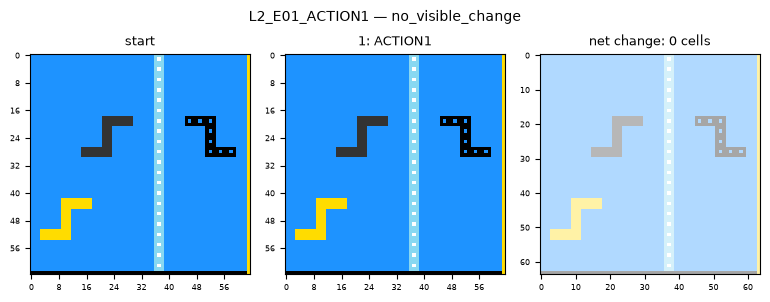

L2_E01_ACTION1: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
   step  1 ACTION1                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)


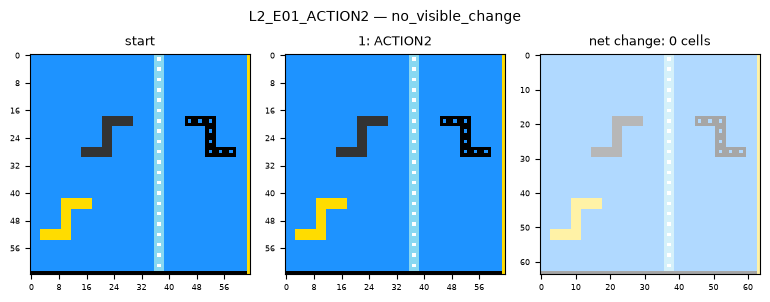

L2_E01_ACTION2: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
   step  1 ACTION2                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)


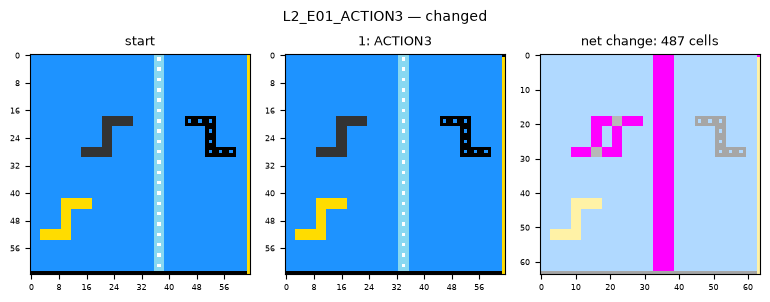

L2_E01_ACTION3: outcome=changed | changed cells per step=[487] | net=487 | net bbox=[9, 0, 63, 62] | objects net=486 | counter cells=1 | final state=NOT_FINISHED
   step  1 ACTION3                     yellow=(-6, 0)  grey=(0, 0)  bar=(-3, 0)  target=(0, 0)


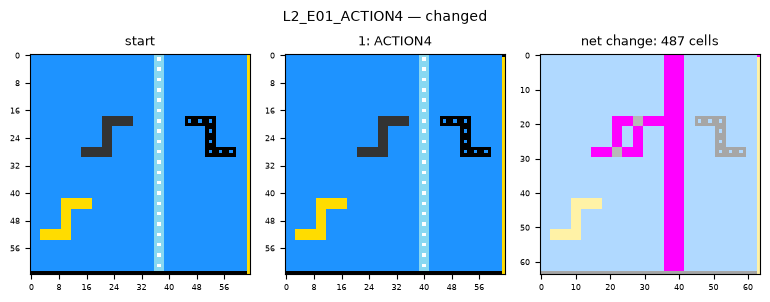

L2_E01_ACTION4: outcome=changed | changed cells per step=[487] | net=487 | net bbox=[15, 0, 63, 62] | objects net=486 | counter cells=1 | final state=NOT_FINISHED
   step  1 ACTION4                     yellow=(6, 0)  grey=(0, 0)  bar=(3, 0)  target=(0, 0)


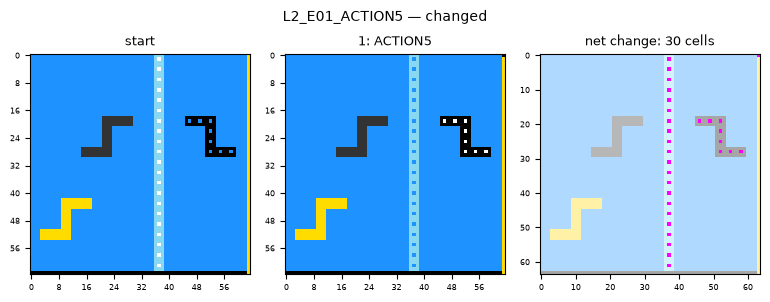

L2_E01_ACTION5: outcome=changed | changed cells per step=[30] | net=30 | net bbox=[37, 0, 63, 61] | objects net=29 | counter cells=1 | final state=NOT_FINISHED
   step  1 ACTION5                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)


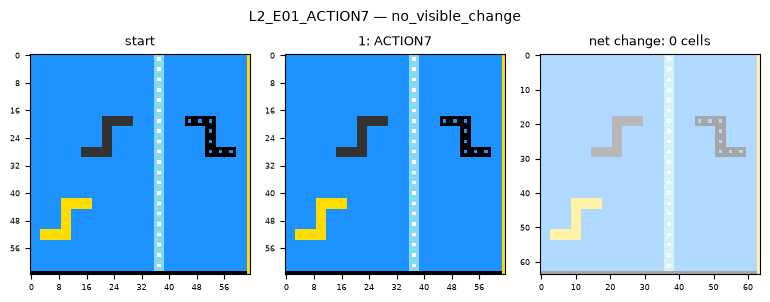

L2_E01_ACTION7: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
   step  1 ACTION7                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)

Observed displacement per action: {
 "ACTION1": {
  "yellow": [
   0,
   0
  ],
  "grey": [
   0,
   0
  ],
  "bar": [
   0,
   0
  ],
  "target": [
   0,
   0
  ]
 },
 "ACTION2": {
  "yellow": [
   0,
   0
  ],
  "grey": [
   0,
   0
  ],
  "bar": [
   0,
   0
  ],
  "target": [
   0,
   0
  ]
 },
 "ACTION3": {
  "yellow": [
   -6,
   0
  ],
  "grey": [
   0,
   0
  ],
  "bar": [
   -3,
   0
  ],
  "target": [
   0,
   0
  ]
 },
 "ACTION4": {
  "yellow": [
   6,
   0
  ],
  "grey": [
   0,
   0
  ],
  "bar": [
   3,
   0
  ],
  "target": [
   0,
   0
  ]
 },
 "ACTION5": {
  "yellow": [
   0,
   0
  ],
  "grey": [
   0,
   0
  ],
  "bar": [
   0,
   0
  ],
  "target": [
   0,
   0
  ]
 },
 "ACTION7": {
  "yellow": [
   0,
   0
  ],
  "grey"

In [7]:
MAPPING = {}
for a in SIMPLE_ACTIONS:
    r = run_experiment(f"L2_E01_{a}", f"Level 2: what does {a} do once?", [(a, {})])
    print_moves(r)
    if r["steps"]:
        MAPPING[a] = moves_table(r)[0][3]
print("\nObserved displacement per action:", json.dumps(MAPPING, indent=1))

### L2_E02 — Repeat each movement ×5
*Question:* what happens when a shape reaches the screen edge or the bar? Does the other shape keep moving?

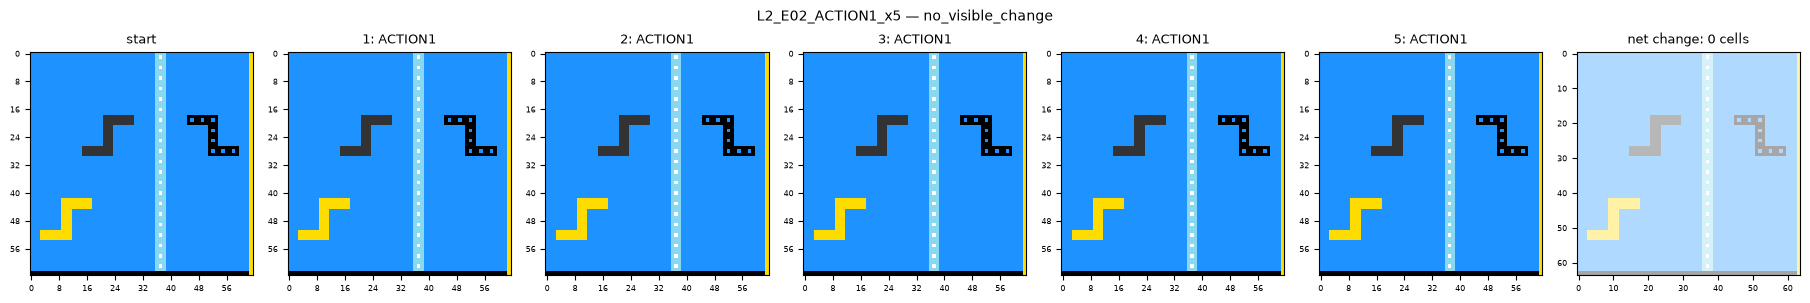

L2_E02_ACTION1_x5: outcome=no_visible_change | changed cells per step=[0, 0, 0, 0, 0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
   step  1 ACTION1                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  2 ACTION1                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  3 ACTION1                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  4 ACTION1                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  5 ACTION1                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)


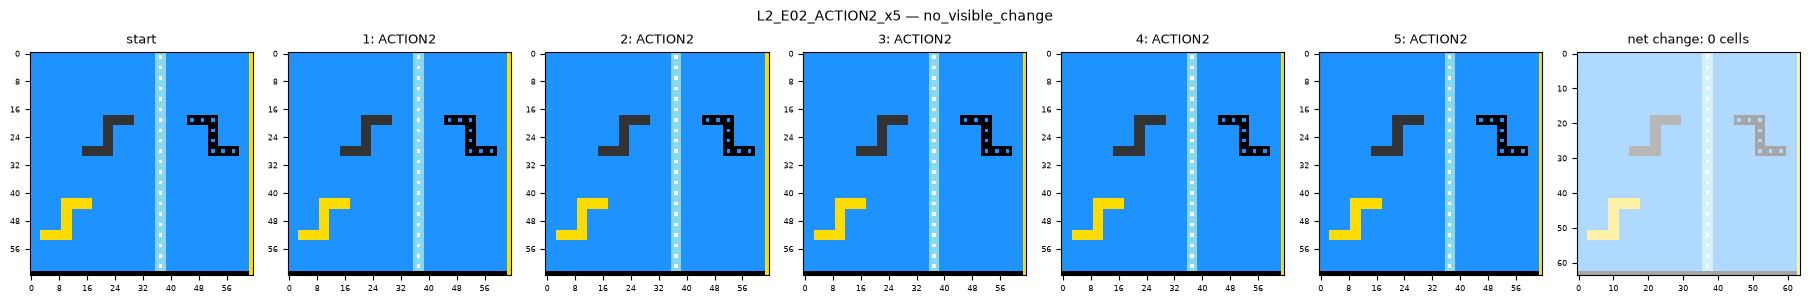

L2_E02_ACTION2_x5: outcome=no_visible_change | changed cells per step=[0, 0, 0, 0, 0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
   step  1 ACTION2                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  2 ACTION2                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  3 ACTION2                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  4 ACTION2                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  5 ACTION2                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)


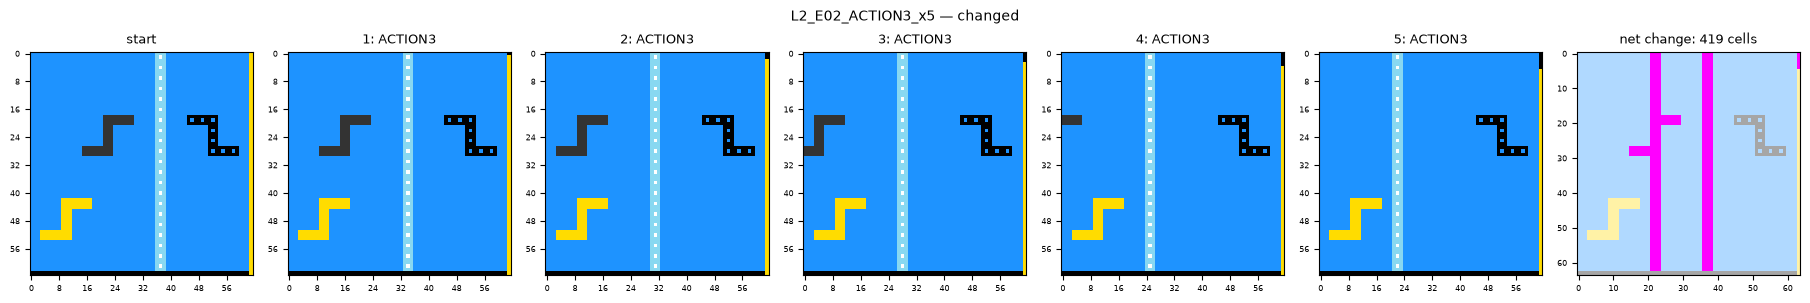

L2_E02_ACTION3_x5: outcome=changed | changed cells per step=[487, 487, 478, 442, 397] | net=419 | net bbox=[15, 0, 63, 62] | objects net=414 | counter cells=5 | final state=NOT_FINISHED
   step  1 ACTION3                     yellow=(-6, 0)  grey=(0, 0)  bar=(-3, 0)  target=(0, 0)
   step  2 ACTION3                     yellow=(-6, 0)  grey=(0, 0)  bar=(-3, 0)  target=(0, 0)
   step  3 ACTION3                     yellow=(-3, 0)  grey=(0, 0)  bar=(-3, 0)  target=(0, 0)
   step  4 ACTION3                     yellow=(0, 0)  grey=(0, 0)  bar=(-3, 0)  target=(0, 0)
   step  5 ACTION3                     yellow=missing  grey=(0, 0)  bar=(-3, 0)  target=(0, 0)


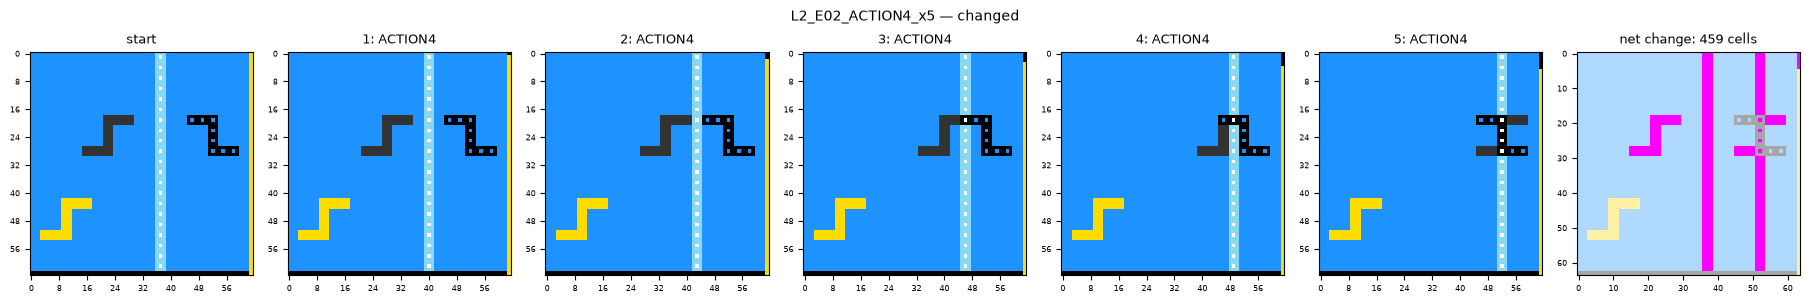

L2_E02_ACTION4_x5: outcome=changed | changed cells per step=[487, 478, 461, 426, 393] | net=459 | net bbox=[15, 0, 63, 62] | objects net=454 | counter cells=5 | final state=NOT_FINISHED
   step  1 ACTION4                     yellow=(6, 0)  grey=(0, 0)  bar=(3, 0)  target=(0, 0)
   step  2 ACTION4                     yellow=(6, 0)  grey=(0, 0)  bar=(3, 0)  target=(0, 0)
   step  3 ACTION4                     yellow=(6, 0)  grey=(0, 0)  bar=(3, 0)  target=(0, 0)
   step  4 ACTION4                     yellow=(6, 3)  grey=(0, 0)  bar=(3, 0)  target=(0, 0)
   step  5 ACTION4                     yellow=(6, -3)  grey=(0, 0)  bar=(3, 0)  target=(0, 0)


In [8]:
for a in [x for x in ("ACTION1", "ACTION2", "ACTION3", "ACTION4") if x in AVAILABLE]:
    r = run_experiment(f"L2_E02_{a}_x5", f"Level 2: is {a} blocked by an edge when repeated 5 times?", [(a, {})] * 5)
    print_moves(r)

### L2_E03 — Does ACTION5 change what the movement actions control?
*Question:* in level 1 ACTION5 only advanced the counter. Here, does it change the effect of the next movement?
Compare with L2_E01.

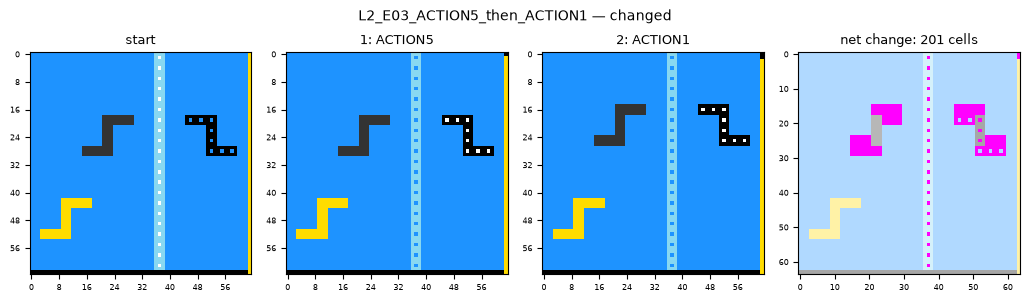

L2_E03_ACTION5_then_ACTION1: outcome=changed | changed cells per step=[30, 181] | net=201 | net bbox=[15, 0, 63, 61] | objects net=199 | counter cells=2 | final state=NOT_FINISHED
   step  1 ACTION5                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  2 ACTION1                     yellow=(0, -3)  grey=(0, -3)  bar=(0, 0)  target=(0, 0)


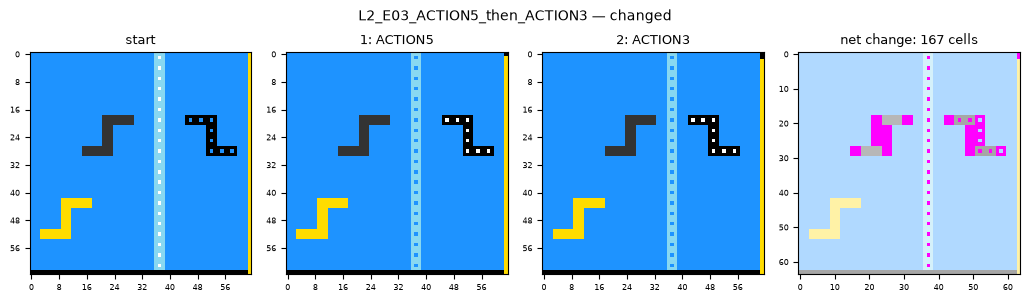

L2_E03_ACTION5_then_ACTION3: outcome=changed | changed cells per step=[30, 145] | net=167 | net bbox=[15, 0, 63, 61] | objects net=165 | counter cells=2 | final state=NOT_FINISHED
   step  1 ACTION5                     yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  2 ACTION3                     yellow=(3, 0)  grey=(-3, 0)  bar=(0, 0)  target=(0, 0)


In [9]:
if "ACTION5" in AVAILABLE:
    for a in [x for x in ("ACTION1", "ACTION3") if x in AVAILABLE]:
        r = run_experiment(f"L2_E03_ACTION5_then_{a}", f"Level 2: after ACTION5, what does {a} move?", [("ACTION5", {}), (a, {})])
        print_moves(r)

### L2_E04 — Clicks
*Question:* do clicks on the bar (now dotted), the shapes, the target or the background do anything?
And does a click on the bar change what a following horizontal move does?

L2_E04_click_yellow: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
L2_E04_click_grey: outcome=changed | changed cells per step=[29] | net=29 | net bbox=[37, 1, 58, 61] | objects net=29 | counter cells=0 | final state=NOT_FINISHED
L2_E04_click_bar: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
L2_E04_click_target: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
L2_E04_click_bar_dot: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED
L2_E04_click_background: outcome=no_visible_change | changed cells per step=[0] | net=0 | net bbox=None | objects net=0 | counter cells=0 | final state=NOT_FINISHED


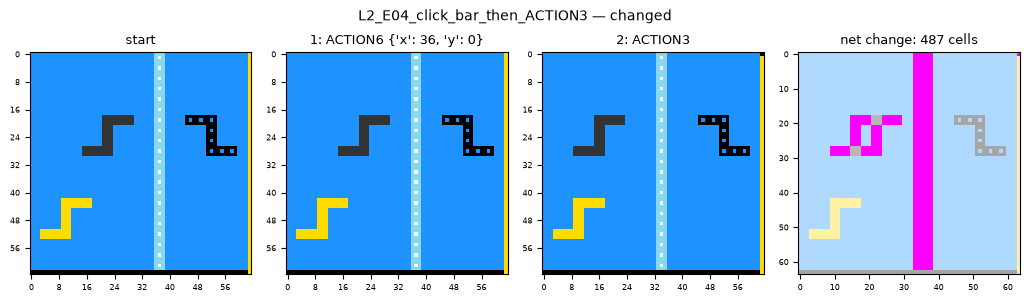

L2_E04_click_bar_then_ACTION3: outcome=changed | changed cells per step=[0, 487] | net=487 | net bbox=[9, 0, 63, 62] | objects net=486 | counter cells=1 | final state=NOT_FINISHED
   step  1 ACTION6  {'x': 36, 'y': 0}  yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  2 ACTION3                     yellow=(-6, 0)  grey=(0, 0)  bar=(-3, 0)  target=(0, 0)


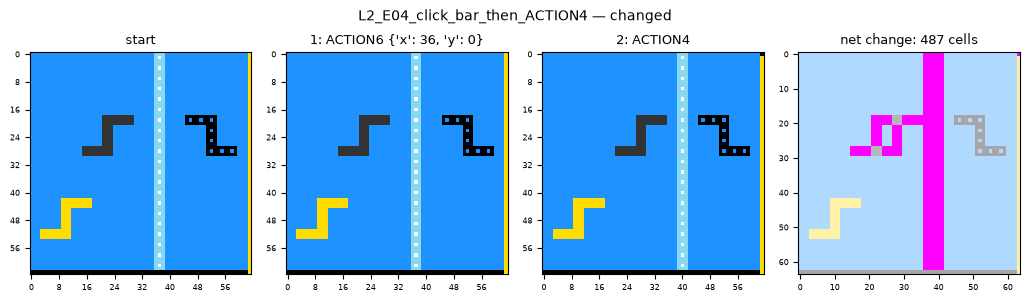

L2_E04_click_bar_then_ACTION4: outcome=changed | changed cells per step=[0, 487] | net=487 | net bbox=[15, 0, 63, 62] | objects net=486 | counter cells=1 | final state=NOT_FINISHED
   step  1 ACTION6  {'x': 36, 'y': 0}  yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  2 ACTION4                     yellow=(6, 0)  grey=(0, 0)  bar=(3, 0)  target=(0, 0)


In [10]:
targets = {}
if "ACTION6" in AVAILABLE:
    for name, p in P0.items():
        if p:
            # click on an actual cell of the object, near its top-left corner
            play = play_area(frame2)[:63, :]
            color = {"yellow": 4, "grey": 5, "bar": 10, "target": 11}[name]
            ys, xs = np.where(play == color)
            i = int(np.argmin((xs - p["x0"]) ** 2 + (ys - p["y0"]) ** 2))
            targets[name] = {"x": int(xs[i]), "y": int(ys[i])}
    dots = np.argwhere(play_area(frame2)[:63, :] == 0)
    if len(dots):
        targets["bar_dot"] = {"x": int(dots[0][1]), "y": int(dots[0][0])}
    targets["background"] = {"x": 5, "y": 5}
    for name, xy in targets.items():
        run_experiment(f"L2_E04_click_{name}", f"Level 2: does clicking the {name} at {xy} do anything?", [("ACTION6", xy)], show=False)
    for a in [x for x in ("ACTION3", "ACTION4") if x in AVAILABLE]:
        if "bar" in targets:
            r = run_experiment(f"L2_E04_click_bar_then_{a}", f"Level 2: after clicking the bar, what does {a} move?",
                               [("ACTION6", targets["bar"]), (a, {})])
            print_moves(r)

### L2_E05 — Apply the level-1 rule directly
*Hypothesis tested (H_L2_1):* moving the yellow shape onto the target with the movement mapping measured in L2_E01
completes level 2, exactly like level 1.
The sequence is computed from the measured mapping — nothing is hard-coded. If a shape gets blocked, the experiment
records it; that is a useful (unsuccessful) result.

In [11]:
def plan_to_target(mapping, start, goal):
    # greedy plan using only actions that move the yellow shape by a pure (dx, 0) or (0, dy)
    dx, dy = goal["x0"] - start["x0"], goal["y0"] - start["y0"]
    seq = []
    for a, d in mapping.items():
        if not isinstance(d.get("yellow"), tuple) and not isinstance(d.get("yellow"), list):
            continue
        mx, my = d["yellow"]
        if mx and not my and dx and (dx > 0) == (mx > 0) and dx % mx == 0:
            seq += [(a, {})] * (dx // mx)
            dx = 0
        elif my and not mx and dy and (dy > 0) == (my > 0) and dy % my == 0:
            seq += [(a, {})] * (dy // my)
            dy = 0
    return seq, (dx, dy)


PLAN, REMAINDER = plan_to_target(MAPPING, P0["yellow"], P0["target"])
print("Yellow:", P0["yellow"], "\nTarget:", P0["target"])
print("Planned:", [a for a, _ in PLAN], "| offset left unplanned:", REMAINDER)
if PLAN and REMAINDER == (0, 0):
    for name, seq in (("vertical_first", sorted(PLAN, key=lambda t: t[0] not in ("ACTION1", "ACTION2"))),
                      ("horizontal_first", sorted(PLAN, key=lambda t: t[0] in ("ACTION1", "ACTION2")))):
        r = run_experiment(f"L2_E05_level1_rule_{name}", "Level 2: does the level-1 rule (yellow onto target) work?", seq)
        print_moves(r)
        end = np.load(FRAMES_DIR / f"{r['experiment_id']}_final.npy")
        print("   final positions:", positions(end))
else:
    print("No pure-axis plan could be built from the measured mapping — see L2_E01/L2_E02.")

Yellow: {'x0': 15, 'y0': 18, 'x1': 29, 'y1': 29, 'cells': 72} 
Target: {'x0': 3, 'y0': 42, 'x1': 17, 'y1': 53, 'cells': 72}
Planned: ['ACTION3', 'ACTION3'] | offset left unplanned: (0, 24)
No pure-axis plan could be built from the measured mapping — see L2_E01/L2_E02.


### L2_E06 — Selection: which object carries the black dots?
*Observed in run 20261120T015752Z:* at the start of level 2 the black dots (colour 0) are on the **bar**, and only
ACTION3/ACTION4 do something: the bar moves 3 cells and the yellow shape 6 cells, the grey shape stays put.
After ACTION5 or a click on the grey shape, the dots appear on the **grey** shape instead (29 cells change = 21 dots
leave the bar + 8 appear on the grey shape).
*Question:* do the dots mark the selected object, and does ACTION5 toggle the selection back and forth?

L2_E06_ACTION5_x1: outcome=changed | changed cells per step=[30] | net=30 | net bbox=[37, 0, 63, 61] | objects net=29 | counter cells=1 | final state=NOT_FINISHED
L2_E06_ACTION5_x2: outcome=changed_then_returned_to_start | changed cells per step=[30, 30] | net=2 | net bbox=[63, 0, 63, 1] | objects net=0 | counter cells=2 | final state=NOT_FINISHED
L2_E06_ACTION5_x3: outcome=changed | changed cells per step=[30, 30, 30] | net=32 | net bbox=[37, 0, 63, 61] | objects net=29 | counter cells=3 | final state=NOT_FINISHED


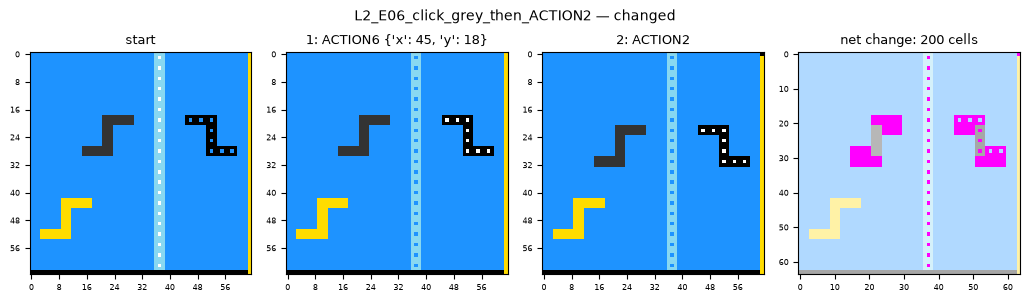

L2_E06_click_grey_then_ACTION2: outcome=changed | changed cells per step=[29, 181] | net=200 | net bbox=[15, 0, 63, 61] | objects net=199 | counter cells=1 | final state=NOT_FINISHED
   step  1 ACTION6  {'x': 45, 'y': 18} yellow=(0, 0)  grey=(0, 0)  bar=(0, 0)  target=(0, 0)
   step  2 ACTION2                     yellow=(0, 3)  grey=(0, 3)  bar=(0, 0)  target=(0, 0)
Dots are on: {'start': 'bar', 'L2_E06_ACTION5_x1': 'grey', 'L2_E06_ACTION5_x2': 'bar', 'L2_E06_ACTION5_x3': 'grey', 'after click on grey': 'grey'}


In [12]:
def dots_on(frame):
    # which tracked object carries the black dots (colour 0)?
    play = play_area(frame)[:63, :]
    ys, xs = np.where(play == 0)
    if len(xs) == 0:
        return None
    pos = positions(frame)
    for name in ("bar", "grey", "yellow"):
        p = pos[name]
        if p and all(p["x0"] <= x <= p["x1"] and p["y0"] <= y <= p["y1"] for x, y in zip(xs, ys)):
            return name
    return "mixed"


SELECTION = {"start": dots_on(frame2)}
for eid, seq in (("L2_E06_ACTION5_x1", [("ACTION5", {})]),
                 ("L2_E06_ACTION5_x2", [("ACTION5", {})] * 2),
                 ("L2_E06_ACTION5_x3", [("ACTION5", {})] * 3)):
    r = run_experiment(eid, "Level 2: does ACTION5 toggle which object carries the dots?", seq, show=False)
    SELECTION[eid] = dots_on(np.load(FRAMES_DIR / f"{eid}_final.npy"))
if "grey" in targets:
    r = run_experiment("L2_E06_click_grey_then_ACTION2", "Level 2: after clicking the grey shape, what does ACTION2 move?",
                       [("ACTION6", targets["grey"]), ("ACTION2", {})])
    print_moves(r)
    SELECTION["after click on grey"] = dots_on(np.load(FRAMES_DIR / "L2_E06_click_grey_then_ACTION2_final.npy"))
print("Dots are on:", SELECTION)

### L2_E07 — Solve level 2 using both selections
*Hypothesis tested (H_L2_solve):* the yellow shape is the mirror image of the grey shape across the bar. So:
1. with the **bar** selected, move the bar horizontally until the yellow shape is above the target (each bar step moves yellow twice as far);
2. select the **grey** shape (ACTION5, or a click — variant b);
3. move it down: the yellow shape follows vertically onto the target.

All counts are computed from the displacements measured above (L2_E01 and L2_E06), not hard-coded.

needed dx=-12, dy=24 | yellow per bar move: {'ACTION3': -6, 'ACTION4': 6} | yellow per ACTION2 with grey selected: 3


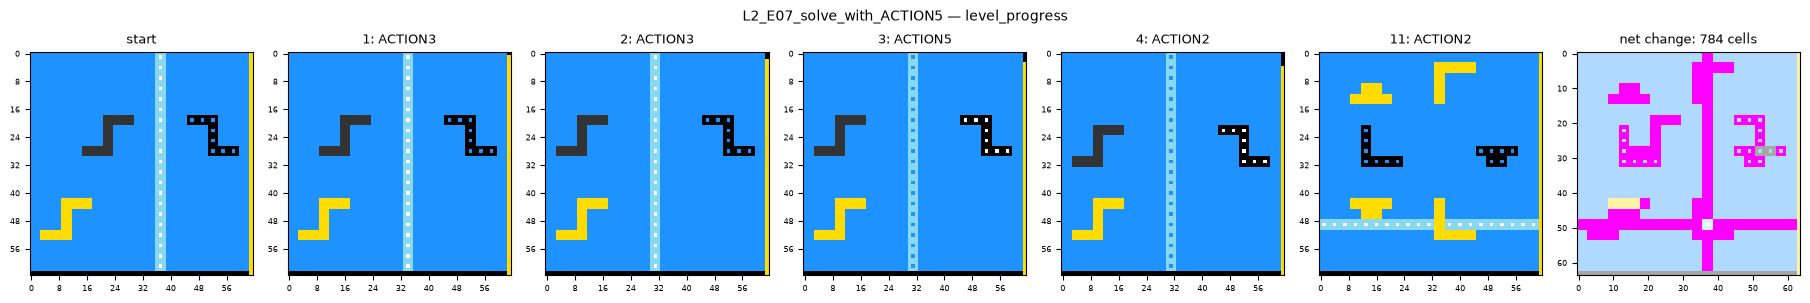

L2_E07_solve_with_ACTION5: outcome=level_progress | changed cells per step=[487, 487, 30, 181, 181, 181, 181, 180, 180, 180, 766] | net=784 | net bbox=[0, 0, 62, 62] | objects net=784 | counter cells=0 | final state=NOT_FINISHED
   levels_completed: 2 | counter cells used: 10 | total actions: 11


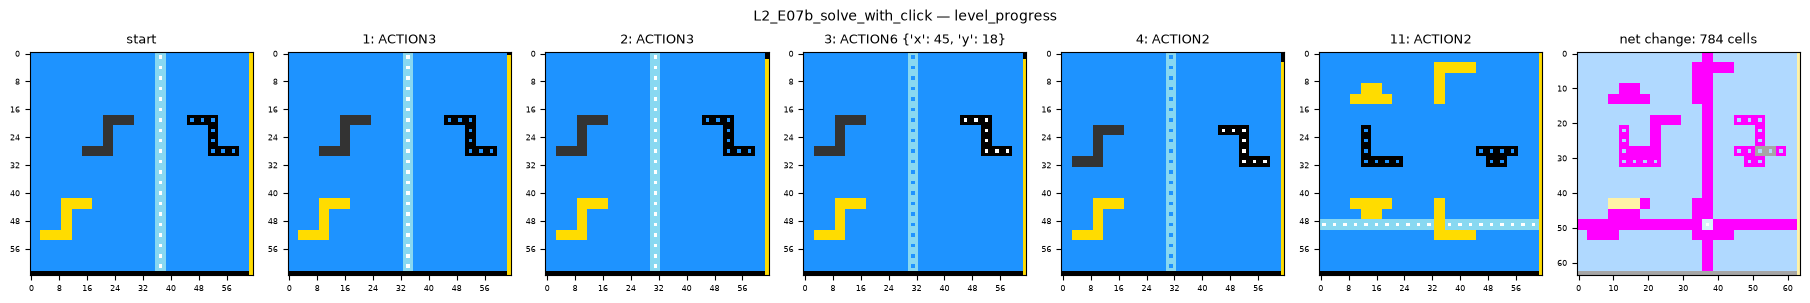

L2_E07b_solve_with_click: outcome=level_progress | changed cells per step=[487, 487, 29, 181, 181, 181, 181, 180, 180, 180, 765] | net=784 | net bbox=[0, 0, 62, 62] | objects net=784 | counter cells=0 | final state=NOT_FINISHED
   levels_completed: 2 | counter cells used: 9 | total actions: 11


In [13]:
yel, tgt = P0["yellow"], P0["target"]
dx, dy = tgt["x0"] - yel["x0"], tgt["y0"] - yel["y0"]

# horizontal: bar selected (start state), measured in L2_E01
hx = {a: MAPPING[a]["yellow"][0] for a in ("ACTION3", "ACTION4") if a in MAPPING and isinstance(MAPPING[a]["yellow"], tuple)}
h_act = next((a for a, m in hx.items() if m and dx % m == 0 and dx // m > 0), None)
# vertical: grey selected, measured in L2_E06 (click then ACTION2)
vy = None
if "L2_E06_click_grey_then_ACTION2" in RESULTS:
    vy = moves_table(RESULTS["L2_E06_click_grey_then_ACTION2"])[1][3]["yellow"][1]
print(f"needed dx={dx}, dy={dy} | yellow per bar move: {hx} | yellow per ACTION2 with grey selected: {vy}")

if h_act is not None and vy and dy % vy == 0 and dy // vy > 0:
    horiz = [(h_act, {})] * (dx // hx[h_act])
    vert = [("ACTION2", {})] * (dy // vy)
    variants = {"L2_E07_solve_with_ACTION5": horiz + [("ACTION5", {})] + vert}
    if "grey" in targets:
        variants["L2_E07b_solve_with_click"] = horiz + [("ACTION6", targets["grey"])] + vert
    for eid, seq in variants.items():
        r = run_experiment(eid, "Level 2: bar to align horizontally, then grey shape down — does it complete level 2?", seq)
        last = r["steps"][-1] if r["steps"] else {}
        print("   levels_completed:", last.get("levels_completed"), "| counter cells used:",
              max((s["counter_cells_used"] for s in r["steps"][:-1]), default=0), "| total actions:", len(seq))
else:
    print("Could not build a plan from the measurements — check L2_E01 / L2_E06 outputs.")

## 4. Observations vs. hypotheses (level 2)

Statuses are set automatically from this run where possible. Others stay `untested` until a dedicated experiment exists.

In [14]:
HYPOTHESES = []


def add(hid, statement, status, evidence):
    HYPOTHESES.append({"id": hid, "statement": statement, "status": status, "evidence": evidence})


# Same controls as level 1?
L1_MAPPING = {"ACTION1": (0, -3), "ACTION2": (0, 3)}
same_vertical = all(isinstance(MAPPING.get(a, {}).get("yellow"), (tuple, list)) and tuple(MAPPING[a]["yellow"]) == v
                    for a, v in L1_MAPPING.items() if a in MAPPING)
add("H_L2_0", "At the start of level 2 (bar selected), ACTION1/ACTION2 still move the yellow shape up/down by 3 cells",
    "supported" if same_vertical else "refuted", f"L2_E01 mapping: { {a: MAPPING.get(a) for a in L1_MAPPING} }")

mirror = all(isinstance(MAPPING.get(a, {}).get("yellow"), (tuple, list)) and isinstance(MAPPING[a].get("grey"), (tuple, list))
             and MAPPING[a]["yellow"][0] == -MAPPING[a]["grey"][0] and MAPPING[a]["yellow"][0] != 0
             for a in ("ACTION3", "ACTION4") if a in MAPPING)
add("H_L2_mirror", "At the start of level 2 (bar selected), ACTION3/ACTION4 still move the yellow and grey shapes in opposite horizontal directions",
    "supported" if mirror else "refuted", f"L2_E01 mapping: { {a: MAPPING.get(a) for a in ('ACTION3', 'ACTION4')} }")

clicks = [k for k in RESULTS if k.startswith("L2_E04_click_") and "_then_" not in k]
if clicks:
    any_effect = [k for k in clicks if RESULTS[k]["outcome"] != "no_visible_change"]
    add("H_L2_click", "Clicks have no effect on level 2 either", "refuted" if any_effect else "supported",
        f"clicks with an effect: {any_effect}" if any_effect else f"{len(clicks)} clicks, none changed anything")

e5 = [RESULTS[k] for k in RESULTS if k.startswith("L2_E05_")]
if e5:
    ok = any(r["outcome"] == "level_progress" for r in e5)
    add("H_L2_1", "Moving the yellow shape onto the target completes level 2 (same rule as level 1)",
        "supported" if ok else "refuted", "; ".join(f"{r['experiment_id']}: {r['outcome']}" for r in e5))
else:
    add("H_L2_1", "Moving the yellow shape onto the target completes level 2 (same rule as level 1)",
        "untested", f"no direct plan from the measured mapping; remainder={REMAINDER}")

bar_moved = all(isinstance(MAPPING.get(a, {}).get("bar"), tuple) and MAPPING[a]["bar"][0] != 0 for a in ("ACTION3", "ACTION4"))
add("H_L2_bar", "At the start of level 2, ACTION3/ACTION4 move the bar (mirror axis) horizontally",
    "supported" if bar_moved else "refuted", f"L2_E01: { {a: MAPPING.get(a, {}).get('bar') for a in ('ACTION3', 'ACTION4')} }")

double = all(isinstance(MAPPING.get(a, {}).get("yellow"), tuple) and isinstance(MAPPING[a].get("bar"), tuple)
             and MAPPING[a]["yellow"][0] == 2 * MAPPING[a]["bar"][0] != 0 for a in ("ACTION3", "ACTION4"))
add("H_L2_axis", "The yellow shape is the mirror image of the grey shape across the bar: moving the bar by d moves yellow by 2d",
    "supported" if double else "refuted", f"L2_E01 yellow vs bar: { {a: (MAPPING.get(a, {}).get('yellow'), MAPPING.get(a, {}).get('bar')) for a in ('ACTION3', 'ACTION4')} }")

sel_ok = (SELECTION.get("start") == "bar" and SELECTION.get("L2_E06_ACTION5_x1") == "grey"
          and SELECTION.get("L2_E06_ACTION5_x2") == "bar" and SELECTION.get("L2_E06_ACTION5_x3") == "grey")
add("H_L2_select", "The black dots mark the selected object; ACTION5 toggles the selection between bar and grey shape",
    "supported" if sel_ok else "refuted", f"dots on: {SELECTION}")
if "after click on grey" in SELECTION:
    add("H_L2_click_select", "Clicking the grey shape selects it (without using a counter cell)",
        "supported" if SELECTION["after click on grey"] == "grey" and RESULTS["L2_E04_click_grey"]["counter_cells_used"] == 0 else "refuted",
        f"dots after click: {SELECTION['after click on grey']}; counter cells used by the click: {RESULTS['L2_E04_click_grey']['counter_cells_used']}")

e7 = [RESULTS[k] for k in RESULTS if k.startswith("L2_E07")]
if e7:
    add("H_L2_solve", "Bar to align horizontally, then grey shape down, completes level 2",
        "supported" if all(r["outcome"] == "level_progress" for r in e7) else "refuted",
        "; ".join(f"{r['experiment_id']}: {r['outcome']} in {len(r['actions'])} actions" for r in e7))

for h in HYPOTHESES:
    print(f"[{h['status']:>12}] {h['id']}: {h['statement']}\n               evidence: {h['evidence']}")

[     refuted] H_L2_0: At the start of level 2 (bar selected), ACTION1/ACTION2 still move the yellow shape up/down by 3 cells
               evidence: L2_E01 mapping: {'ACTION1': {'yellow': (0, 0), 'grey': (0, 0), 'bar': (0, 0), 'target': (0, 0)}, 'ACTION2': {'yellow': (0, 0), 'grey': (0, 0), 'bar': (0, 0), 'target': (0, 0)}}
[     refuted] H_L2_mirror: At the start of level 2 (bar selected), ACTION3/ACTION4 still move the yellow and grey shapes in opposite horizontal directions
               evidence: L2_E01 mapping: {'ACTION3': {'yellow': (-6, 0), 'grey': (0, 0), 'bar': (-3, 0), 'target': (0, 0)}, 'ACTION4': {'yellow': (6, 0), 'grey': (0, 0), 'bar': (3, 0), 'target': (0, 0)}}
[     refuted] H_L2_click: Clicks have no effect on level 2 either
               evidence: clicks with an effect: ['L2_E04_click_grey']
[    untested] H_L2_1: Moving the yellow shape onto the target completes level 2 (same rule as level 1)
               evidence: no direct plan from the measured mapping; rema

## 5. Unsuccessful experiments

In [15]:
failed = [r for r in RESULTS.values() if r["outcome"] in {"error", "no_visible_change", "game_over"}]
print(f"{len(failed)} unsuccessful experiment(s)\n")
for r in failed:
    acts = ", ".join(f"{a['action']}{a['action_data'] or ''}" for a in r["actions"][:5])
    print(f"• {r['experiment_id']}: {r['outcome']} — {acts}" + (f" — {r['error']}" if r["error"] else ""))

10 unsuccessful experiment(s)

• L2_E01_ACTION1: no_visible_change — ACTION1
• L2_E01_ACTION2: no_visible_change — ACTION2
• L2_E01_ACTION7: no_visible_change — ACTION7
• L2_E02_ACTION1_x5: no_visible_change — ACTION1, ACTION1, ACTION1, ACTION1, ACTION1
• L2_E02_ACTION2_x5: no_visible_change — ACTION2, ACTION2, ACTION2, ACTION2, ACTION2
• L2_E04_click_yellow: no_visible_change — ACTION6{'x': 21, 'y': 18}
• L2_E04_click_bar: no_visible_change — ACTION6{'x': 36, 'y': 0}
• L2_E04_click_target: no_visible_change — ACTION6{'x': 9, 'y': 42}
• L2_E04_click_bar_dot: no_visible_change — ACTION6{'x': 37, 'y': 1}
• L2_E04_click_background: no_visible_change — ACTION6{'x': 5, 'y': 5}


## 6. Report

Fill `DISCOVERIES` after reading the outputs above (facts only, each citing an experiment ID), then run the last cell.

In [16]:
DISCOVERIES = [
    "RESET from level 2 goes back to level 1 (full_reset=True, levels_completed=0); level 2 is reached again by replaying the 15 level-1 moves (goto_level2 log).",
    "The black dots (colour 0) mark the selected object. At the start of level 2 the bar is selected (run 20261120T015752Z).",
    "With the bar selected: ACTION3/ACTION4 move the bar 3 cells left/right and the yellow shape 6 cells the same way; the grey shape does not move. ACTION1/ACTION2 do nothing and do not use a counter cell (L2_E01).",
    "ACTION5 moves the selection to the grey shape (21 dots leave the bar, 8 appear on the grey shape) and uses one counter cell (L2_E01_ACTION5).",
    "Clicking the grey shape also selects it, without using a counter cell; clicks on the yellow shape, bar, target or background do nothing (L2_E04).",
    "With the grey shape selected, the controls work like level 1: ACTION1 = both shapes up 3, ACTION3 = grey left / yellow right (L2_E03).",
    "Interpretation consistent with all of the above: the yellow shape is the reflection of the grey shape in the bar (mirror).",
    "The yellow shape can leave the screen on the left (L2_E02_ACTION3_x5, step 5: yellow no longer visible).",
    "LEVEL 2 SOLVED in 11 actions: 2 x ACTION3 (bar left, yellow 12 cells left), select the grey shape (ACTION5 or click), 8 x ACTION2 (L2_E07, L2_E07b).",
]
OPEN_QUESTIONS = [
    "Was the grey shape the selected object in level 1 too (it carried the dots)? Could ACTION5 have selected the bar there?",
    "What happens when the counter column is full?",
    "What new mechanism does level 3 introduce?",
]

In [17]:
def md_table(rows, headers):
    out = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    out += ["| " + " | ".join(str(c).replace("|", "/") for c in row) + " |" for row in rows]
    return "\n".join(out)


exp_rows = []
for r in RESULTS.values():
    acts = ", ".join(f"{a['action']}{a['action_data'] or ''}" for a in r["actions"][:4])
    if len(r["actions"]) > 4:
        acts += f", … ({len(r['actions'])} total)"
    exp_rows.append([r["experiment_id"], acts, [s["changed_cells"] for s in r["steps"]][:6],
                     r["net_change_play_area"]["changed_cells"], r["outcome"]])

report = f'''# AR25 level 2 exploration report — Teammate 2

- **Run ID:** `{RUN_ID}`
- **Raw data:** `{OUT.relative_to(ROOT).as_posix()}/`
- **How level 2 is reached:** reset + level-1 solution (10 × ACTION2, 5 × ACTION3) from `teammate_2_exploration.ipynb`.
- **Reset behaviour:** {RESET_LOG[:2]}

## Level-2 start positions
```json
{json.dumps(P0, indent=1)}
```

## Measured displacement per action (dx, dy of each object's top-left corner)
{md_table([[a, d] for a, d in MAPPING.items()], ["action", "displacement"])}

## Experiments ({len(RESULTS)})
{md_table(exp_rows, ["id", "actions", "changed cells per step", "objects net change", "outcome"])}

## Hypotheses
{md_table([[h["id"], h["statement"], h["status"], h["evidence"]] for h in HYPOTHESES], ["id", "hypothesis", "status", "evidence"])}

## Unsuccessful experiments ({len(failed)})
{chr(10).join(f"- `{r['experiment_id']}` — {r['outcome']}" for r in failed) or "- none"}

## Discoveries
{chr(10).join("- " + d for d in DISCOVERIES) or "- _(not filled in yet)_"}

## Open questions
{chr(10).join("- " + q for q in OPEN_QUESTIONS)}
'''
path = REPORTS_DIR / "teammate_2_level2_report.md"
path.write_text(report, encoding="utf-8")
print("Report written to", path.relative_to(ROOT))
print("Experiments:", len(RESULTS), "| unsuccessful:", len(failed), "| hypotheses:", len(HYPOTHESES))

Report written to reports\teammate_2_level2_report.md
Experiments: 26 | unsuccessful: 10 | hypotheses: 9
